In [39]:
import pandas as pd

In [40]:
raw = pd.read_csv('./libras_abt.csv', dtype=str)
raw.info()
raw.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50186 entries, 0 to 50185
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v0001   50186 non-null  object
 1   c006    50186 non-null  object
 2   c008    50186 non-null  object
 3   c009    50186 non-null  object
 4   d001    50186 non-null  object
 5   c011    50186 non-null  object
 6   d00901  50186 non-null  object
 7   g058    50186 non-null  object
 8   g05801  50186 non-null  object
 9   n       50186 non-null  object
dtypes: object(10)
memory usage: 3.8+ MB


,v0001,c006,c008,c009,d001,c011,d00901,g058,g05801,n
0,35,2,19,1,1,4,10,1,2,146977.5553742569
1,35,1,22,4,1,4,10,1,2,136834.93590607785
2,35,1,30,1,1,1,10,1,2,123619.32724146925


In [41]:
# https://stackoverflow.com/a/20250996
weights = raw['n'].astype(float)
abt = raw.copy()
abt.drop(columns=['n'], inplace=True)
abt["g05801"].replace({'1': "Yes", '2': "No"}, inplace=True)
abt.info()
abt.head(3)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50186 entries, 0 to 50185
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v0001   50186 non-null  object
 1   c006    50186 non-null  object
 2   c008    50186 non-null  object
 3   c009    50186 non-null  object
 4   d001    50186 non-null  object
 5   c011    50186 non-null  object
 6   d00901  50186 non-null  object
 7   g058    50186 non-null  object
 8   g05801  50186 non-null  object
dtypes: object(9)
memory usage: 3.4+ MB


,v0001,c006,c008,c009,d001,c011,d00901,g058,g05801
0,35,2,19,1,1,4,10,1,No
1,35,1,22,4,1,4,10,1,No
2,35,1,30,1,1,1,10,1,No


In [42]:
from pycaret.classification import *
from imblearn.combine import *

In [43]:
s = setup(
    abt, 
    target = 'g05801', 
    fix_imbalance=True, 
    session_id = 123,
    categorical_features=['v0001','c006','c008','c009','d001','c011','d00901','g058']
)

,Description,Value
0,Session id,123
1,Target,g05801
2,Target type,Binary
3,Target mapping,"No: 0, Yes: 1"
4,Original data shape,"(50186, 9)"
5,Transformed data shape,"(83094, 34)"
6,Transformed train set shape,"(68038, 34)"
7,Transformed test set shape,"(15056, 34)"
8,Categorical features,8
9,Preprocess,True


In [32]:
# https://github.com/pycaret/pycaret/issues/1350#issuecomment-1261343673
# Get index of train data  
# idx = get_config('X_train').index
# best = compare_models(fit_kwargs={'sample_weight': weights[idx]})

In [44]:
best = compare_models()

,Model,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC,TT (Sec)
dummy,Dummy Classifier,0.9684,0.5000,0.9684,0.9377,0.9528,0.0000,0.0000,0.1960
catboost,CatBoost Classifier,0.9675,0.7583,0.9675,0.9415,0.9526,0.0048,0.0144,23.3550
lightgbm,Light Gradient Boosting Machine,0.9670,0.7640,0.9670,0.9426,0.9526,0.0119,0.0272,160.7450
xgboost,Extreme Gradient Boosting,0.9573,0.7477,0.9573,0.9421,0.9492,0.0441,0.0488,0.5470
dt,Decision Tree Classifier,0.9218,0.5145,0.9218,0.9401,0.9307,0.0204,0.0211,0.3010
rf,Random Forest Classifier,0.9163,0.6479,0.9163,0.9405,0.9280,0.0260,0.0274,2.1200
et,Extra Trees Classifier,0.9025,0.5539,0.9025,0.9409,0.9208,0.0295,0.0325,2.4960
knn,K Neighbors Classifier,0.8245,0.6279,0.8245,0.9453,0.8774,0.0525,0.0751,0.8770
gbc,Gradient Boosting Classifier,0.8192,0.7580,0.8192,0.9521,0.8751,0.0980,0.1459,2.6270
ada,Ada Boost Classifier,0.7436,0.7564,0.7436,0.9551,0.8269,0.0816,0.1475,0.8630


In [45]:
cb = create_model('catboost')

,Accuracy,AUC,Recall,Prec.,F1,Kappa,MCC
Fold,,,,,,,
0,0.9684,0.7495,0.9684,0.9539,0.9534,0.0166,0.0639
1,0.9667,0.7562,0.9667,0.9378,0.9520,-0.0033,-0.0075
2,0.9681,0.7983,0.9681,0.9378,0.9527,-0.0006,-0.0030
3,0.9673,0.7254,0.9673,0.9378,0.9523,-0.0022,-0.0061
4,0.9675,0.7488,0.9675,0.9378,0.9524,-0.0017,-0.0053
5,0.9670,0.7384,0.9670,0.9378,0.9521,-0.0027,-0.0068
6,0.9678,0.7524,0.9678,0.9459,0.9531,0.0152,0.0422
7,0.9678,0.7844,0.9678,0.9459,0.9531,0.0152,0.0422
8,0.9670,0.7482,0.9670,0.9378,0.9521,-0.0027,-0.0068


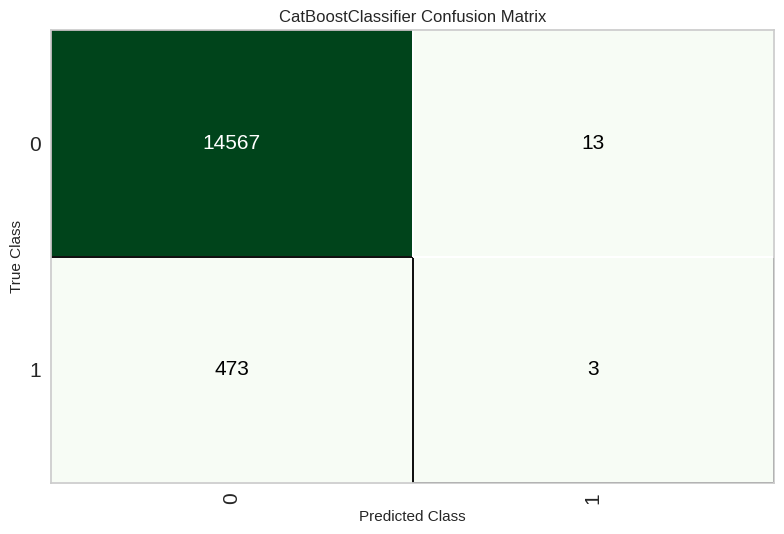

In [46]:
plot_model(cb, plot="confusion_matrix")

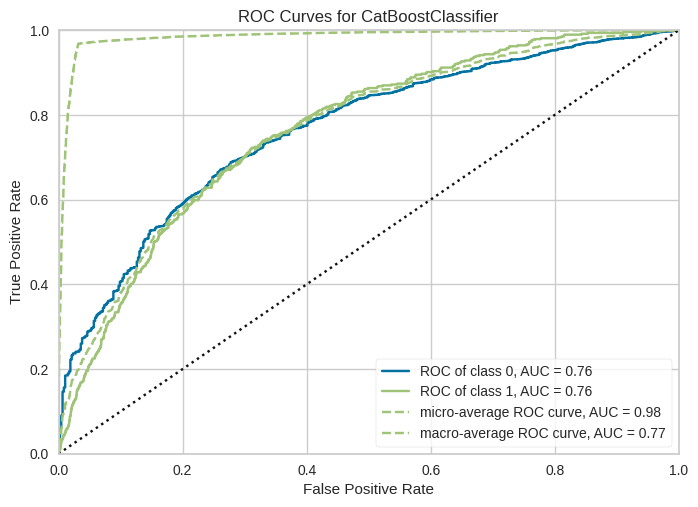

In [48]:
plot_model(cb, plot="auc")

In [ ]:
calib_cb = calibrate_model(cb)

,,
,,
Initiated,. . . . . . . . . . . . . . . . . .,21:38:33
Status,. . . . . . . . . . . . . . . . . .,Fitting 10 Folds
Estimator,. . . . . . . . . . . . . . . . . .,CatBoost Classifier


Processing:   0%|          | 0/6 [00:00<?, ?it/s]